In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent

DATA_FILE = ROOT / "data" / "processed" / "product_reviews_cleaned.csv"
CHART_DIR = ROOT / "visualizations"
CHART_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_FILE)

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("Data Type"))

print("\nFirst five records:")
display(df.head())

print("\nMissing values:")
display(df.isna().sum().to_frame("Missing Count"))

print("\nSummary statistics:")
display(df.describe(include="all").T)

Dataset shape: (170674, 10)

Columns: ['product_name', 'product_price', 'rate', 'review', 'summary', 'sentiment', 'review_length', 'summary_length', 'rating_group', 'review_length_outlier']

Data types:


,Data Type
product_name,str
product_price,float64
rate,int64
review,str
summary,str
sentiment,str
review_length,int64
summary_length,int64
rating_group,str
review_length_outlier,bool



First five records:


,product_name,product_price,rate,review,summary,sentiment,review_length,summary_length,rating_group,review_length_outlier
0,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5,super!,great cooler excellent air flow and for this p...,positive,6,94,High (4-5),False
1,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,5,awesome,best budget 2 fit cooler nice cooling,positive,7,37,High (4-5),False
2,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3,fair,the quality is good but the power of air is de...,positive,4,50,Medium (3),False
3,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,1,useless product,very bad product its a only a fan,negative,15,33,Low (1-2),False
4,Candes 12 L Room/Personal Air Cooler??????(Whi...,3999.0,3,fair,ok ok product,neutral,4,13,Medium (3),False



Missing values:


,Missing Count
product_name,0
product_price,0
rate,0
review,16202
summary,10
sentiment,0
review_length,0
summary_length,0
rating_group,0
review_length_outlier,0



Summary statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
product_name,170674,958,cello Pack of 18 Opalware Cello Dazzle Lush Fi...,4362,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_price,170674.0,NaN,NaN,NaN,4488.546393,10269.255061,59.0,349.0,849.0,3499.0,86990.0
rate,170674.0,NaN,NaN,NaN,4.060033,1.356657,1.0,4.0,5.0,5.0,5.0
review,154472,1321,wonderful,7624,NaN,NaN,NaN,NaN,NaN,NaN,NaN
summary,170664,92920,good,7088,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sentiment,170674,3,positive,134699,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_length,170674.0,NaN,NaN,NaN,11.457398,6.099393,0.0,9.0,11.0,16.0,140.0
summary_length,170674.0,NaN,NaN,NaN,48.079971,75.302242,0.0,11.0,21.0,49.0,497.0
rating_group,170674,3,High (4-5),130212,NaN,NaN,NaN,NaN,NaN,NaN,NaN
review_length_outlier,170674,2,False,170101,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,rate,review_count
0,1,19880
1,2,6193
2,3,14389
3,4,33551
4,5,96661


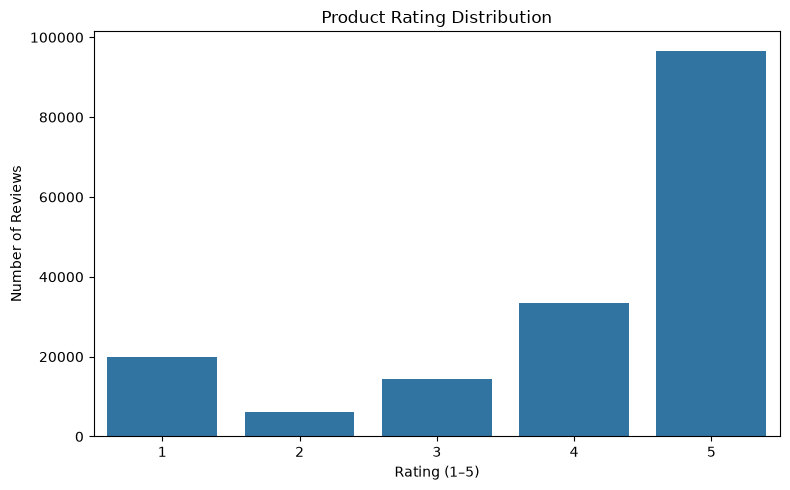

In [2]:
rating_summary = (
    df.groupby("rate")
    .size()
    .reset_index(name="review_count")
    .sort_values("rate")
)

display(rating_summary)

plt.figure(figsize=(8, 5))
sns.barplot(data=rating_summary, x="rate", y="review_count")
plt.title("Product Rating Distribution")
plt.xlabel("Rating (1–5)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

,count,mean,median
sentiment,,,
positive,134699,4.60,5.0
neutral,9503,3.28,3.0
negative,26472,1.61,1.0


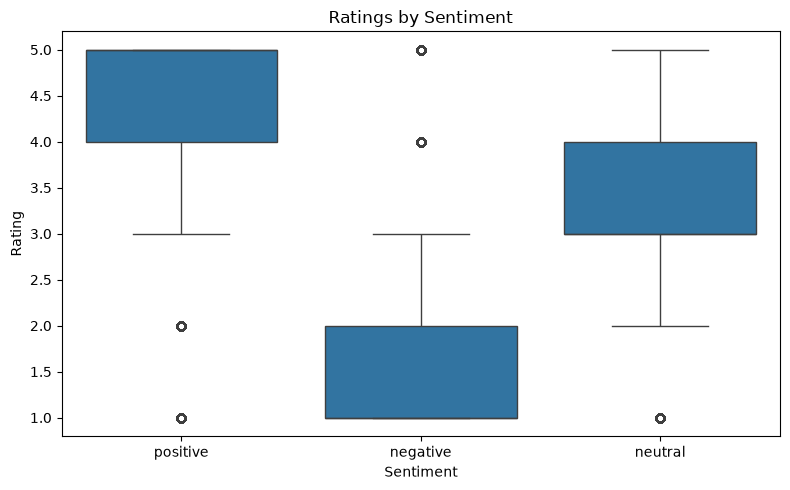

In [3]:
sentiment_summary = (
    df.groupby("sentiment", dropna=False)["rate"]
    .agg(["count", "mean", "median"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(sentiment_summary)

plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="sentiment", y="rate")
plt.title("Ratings by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

Top 10 most-reviewed products:


,review_count,average_rating,median_rating,product_price
product_name,,,,
"cello Pack of 18 Opalware Cello Dazzle Lush Fiesta Opalware Dinner Set, 18 Pieces Dinner SetÃÂ ÃÂ (White, Microwave Safe)",4362,4.27,5.0,1299.0
"Lakm?? Eyeconic Kajal Twin Pack??????????(Deep Black, 0.7 g)",2805,4.48,5.0,218.0
Mi 5A 80 cm (32 inch) HD Ready LED Smart Android TV with Dolby Audio (2022 Model),2122,4.13,5.0,13999.0
Singer FM 1409 Electric Sewing MachineÐÒ?ÐÓ®ÐÂ ÐÒ?ÐÓ®ÐÂ ( Built-in Stitches 9),1743,4.32,5.0,8499.0
"Canon EOS 3000D DSLR Camera 1 Camera Body, 18 - 55 mm Lens????????(Black)",1646,4.45,5.0,30999.0
cello Pack of 18 Opalware Cello Dazzle Lush Fiesta Opalware Dinner Set 18 Pieces Dinner SetWhite Microwave Safe,1642,4.34,5.0,1299.0
"NIVIA Storm Football - Size: 5ÐÓ®ÐÂ ÐÓ®ÐÂ (Pack of 1, Multicolor)",1613,4.04,5.0,429.0
"POCO C31 (Royal Blue, 64 GB)?ÐÒÐÒ?ÐÒÐÒ(4 GB RAM)",1569,3.87,4.0,7499.0
DOMS Pencil Smart Kit,1545,4.70,5.0,449.0


Products with at least 30 reviews and lowest average ratings:


,review_count,average_rating,median_rating,product_price
product_name,,,,
realme 4k Smart Google TV Stick (Black)????(Black),100,2.25,1.0,3999.0
PrintStar 12A / Q2612A Compatible Toner Cartridge For Hp1005 Canon 2900B Black Ink Cartridge,100,2.29,1.0,489.0
Medaline 250 Watt Ultra Thin Slim Ip66 LED Flood Outdoor Light Cool White Waterproof 200WPack of 1 Flood Light Outdoor LampBlack,51,2.49,1.0,565.0
POOJA Maroon PP Polypropylene Area Rug53 cm X 153 cm Rectangle,92,2.62,2.0,295.0
Riyahandlooms Cotton Floor MatBlue Large Pack of 2,188,2.62,3.0,189.0
"TXOR NEXUS with Heart Rate & BP Monitor 35mm Screen Black SmartwatchÐÒ?ÐÓ®ÐÂ ÐÒ?ÐÓ®ÐÂ (Black Strap, Standard)",35,2.63,1.0,759.0
BALKRISHNA ENTERPRISE Green Tea Sticks Face Shaping Mask Face Shaping Mask,99,2.67,1.0,189.0
Prerana Microfibre Solid Cushion Pack of 5White,185,2.68,2.0,258.0
"Aquagrand SkyLand 18 Ltr RO UV UF TDS Water Purifier 18 L RO UV UF TDS Water PurifierÐÒ?ÐÓ®ÐÂ ÐÒ?ÐÓ®ÐÂ (White, Blue)",198,2.69,1.0,4687.0


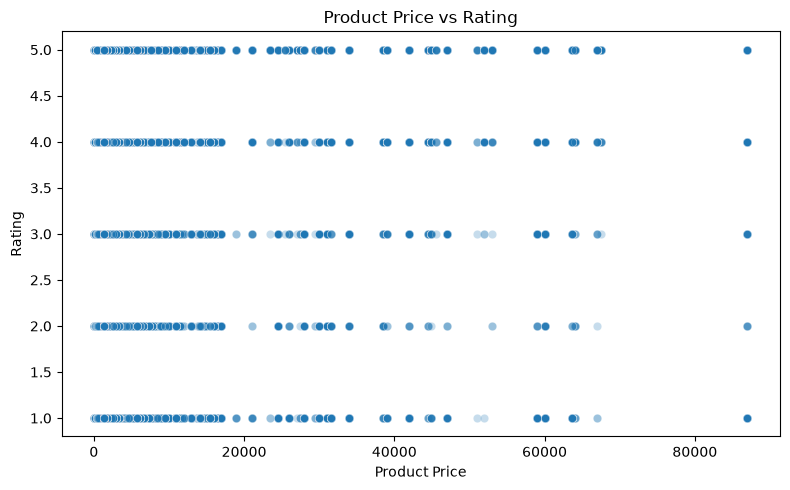

In [4]:
product_summary = (
    df.groupby("product_name")
    .agg(
        review_count=("rate", "size"),
        average_rating=("rate", "mean"),
        median_rating=("rate", "median"),
        product_price=("product_price", "median")
    )
    .round(2)
    .sort_values("review_count", ascending=False)
)

print("Top 10 most-reviewed products:")
display(product_summary.head(10))

print("Products with at least 30 reviews and lowest average ratings:")
display(
    product_summary[product_summary["review_count"] >= 30]
    .sort_values("average_rating")
    .head(10)
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="product_price",
    y="rate",
    alpha=0.25
)
plt.title("Product Price vs Rating")
plt.xlabel("Product Price")
plt.ylabel("Rating")
plt.tight_layout()
plt.show()

Review length statistics:


count    170674.000000
mean         11.457398
std           6.099393
min           0.000000
25%           9.000000
50%          11.000000
75%          16.000000
max         140.000000
Name: review_length, dtype: float64

Long reviews flagged: 573


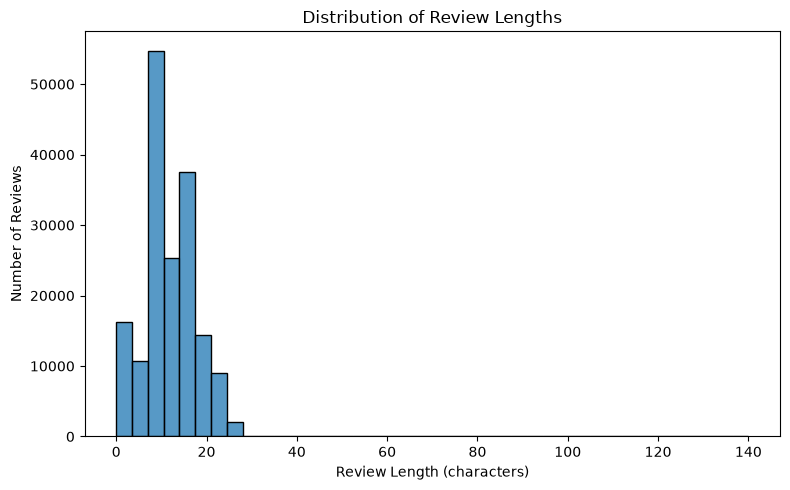

In [5]:
df["review_length"] = df["review"].fillna("").str.len()
df["summary_length"] = df["summary"].fillna("").str.len()

df["rating_group"] = pd.cut(
    df["rate"],
    bins=[0, 2, 3, 5],
    labels=["Low (1–2)", "Medium (3)", "High (4–5)"]
)

q1 = df["review_length"].quantile(0.25)
q3 = df["review_length"].quantile(0.75)
iqr = q3 - q1
upper_limit = q3 + 1.5 * iqr

df["long_review_flag"] = df["review_length"] > upper_limit

print("Review length statistics:")
display(df["review_length"].describe())

print("Long reviews flagged:", int(df["long_review_flag"].sum()))

plt.figure(figsize=(8, 5))
sns.histplot(df["review_length"], bins=40)
plt.title("Distribution of Review Lengths")
plt.xlabel("Review Length (characters)")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

In [6]:
OUTPUT_FILE = ROOT / "data" / "processed" / "product_reviews_eda.csv"
df.to_csv(OUTPUT_FILE, index=False)

print("Saved engineered dataset to:", OUTPUT_FILE)

Saved engineered dataset to: h:\Data-Science\DS Sprint Assessment\data\processed\product_reviews_eda.csv
